# Heterogeneous agents with SIPP

Three animations on `path_planning/maps/2d/2d.yaml` (discrete 4-neighbour grid roadmap), all solved with the
centralized `SippPlanner` through `solve_mapf`. Agents carry their own optional `radius` / `velocity`
keys; missing keys fall back to the scalar `agent_radius` / `agent_velocity` of the solver config.

* The roadmap is inflated with the **largest** agent radius (`max_agent_radius`).
* Two agents collide when their centre distance is below **`r_i + r_j`** (the circles drawn below are the true body radii).
* Each agent moves at its own speed: edge traversal time is `length / v_i`.

Three agents share a 17 x 12 room: `west` drives left to right, `east` swaps head-on with it on the same row, and
`north` cuts vertically through both paths.

In [1]:
import os, math
from copy import deepcopy
import numpy as np
from IPython.display import Image, display

from path_planning.utils.util import (read_graph_sampler_from_yaml, set_global_seed, max_agent_radius,
                                      agent_radii_dict, agent_velocities_dict)
from path_planning.multi_agent_planner.mapf_solver import solve_mapf
from path_planning.utils.checker import check_collision
from path_planning.common.visualizer.visualizer_2d import Visualizer2D

MAP_YAML = "path_planning/maps/2d/2d.yaml"
OUT_DIR = "figs/hetero_sipp"
os.makedirs(OUT_DIR, exist_ok=True)

# Starts / goals shared by the three scenarios (cell centres in the middle room).
ROUTES = {
    "west":  ((23.5, 7.5), (37.5, 7.5)),   # left  -> right
    "east":  ((37.5, 7.5), (23.5, 7.5)),   # right -> left, head-on with "west"
    "north": ((30.5, 3.5), (30.5, 12.5)),  # bottom -> top, cuts through both
}
COLORS = ["tab:orange", "tab:blue", "tab:green"]


def make_agents(radii, velocities):
    """Agent dicts with per-agent radius / velocity (None -> key omitted, scalar fallback)."""
    agents = []
    for name, (start, goal) in ROUTES.items():
        a = {"name": name, "start": list(start), "goal": list(goal)}
        if radii.get(name) is not None:
            a["radius"] = float(radii[name])
        if velocities.get(name) is not None:
            a["velocity"] = float(velocities[name])
        agents.append(a)
    return agents


def build_map(agents, default_radius):
    """Grid roadmap inflated for the largest agent (same recipe as scripts/mapf/run_sipp.py)."""
    set_global_seed(42)
    map_ = read_graph_sampler_from_yaml(MAP_YAML, use_discrete_space=True)
    map_.inflate_obstacles(radius=max_agent_radius(agents, default_radius) + np.sqrt(2) / 2)
    map_.set_parameters(sample_num=0, num_neighbors=4.0, min_edge_len=0.0, max_edge_len=1.1)
    map_.set_start([a["start"] for a in agents])
    map_.set_goal([a["goal"] for a in agents])
    nodes = map_.generateRandomNodes(generate_grid_nodes=True)
    road_map = map_.generate_roadmap(nodes)
    map_.set_constraint_sweep()
    return map_, nodes, road_map


def run_scenario(tag, radii, velocities, default_radius=0.3, default_velocity=1.0,
                 intermediate_frames=4, speed=2, dpi=90):
    agents = make_agents(radii, velocities)
    map_, nodes, road_map = build_map(agents, default_radius)
    summary = solve_mapf(map_, agents, {
        "mapf_solver_name": "sipp", "time_limit": 60, "max_iterations": 10000,
        "agent_radius": default_radius, "agent_velocity": default_velocity, "heuristic_type": "euclidean",
    })
    assert summary["success"], summary.get("failure_reason", "SIPP failed")
    sched = summary["schedule"]
    r_dict, v_dict = summary["agent_radii"], summary["agent_velocities"]
    print(f"[{tag}] inflation radius {map_.inflation_radius:.3f} | makespan {summary['makespan']:.2f} | "
          f"collisions at r_i + r_j: {len(check_collision(sched, r_dict, verbose=False))}")
    for name, path in sched.items():
        speeds = sorted({round(math.dist((a['x'], a['y']), (b['x'], b['y'])) / (b['t'] - a['t']), 3)
                         for a, b in zip(path, path[1:]) if b['t'] > a['t'] and (a['x'], a['y']) != (b['x'], b['y'])})
        print(f"   {name:6s} radius {r_dict[name]:.2f}  nominal speed {v_dict[name]:.2f}  "
              f"observed move speeds {speeds}  arrives t={path[-1]['t']:.2f}")

    gif = os.path.join(OUT_DIR, f"sipp_{tag}.gif")
    vis = Visualizer2D()
    vis.animate(gif, map_, {"schedule": deepcopy(sched)}, road_map=road_map, skip_frames=1,
                intermediate_frames=intermediate_frames, speed=speed, radius=r_dict,  # per-agent circle sizes
                map_frame=False, agent_colors=COLORS, writer="pillow", dpi=dpi)
    vis.close()
    return gif, summary


## 1. Different radii, same speed

Radii 0.25 / 0.45 / 0.70 (clearances 0.70, 0.95 and 1.15 between the pairs), every agent at speed 1.0.

[radii] inflation radius 1.414 | makespan 16.00 | collisions at r_i + r_j: 0
   west   radius 0.25  nominal speed 1.00  observed move speeds [1.0]  arrives t=16.00
   east   radius 0.45  nominal speed 1.00  observed move speeds [1.0]  arrives t=14.00
   north  radius 0.70  nominal speed 1.00  observed move speeds [1.0]  arrives t=9.00


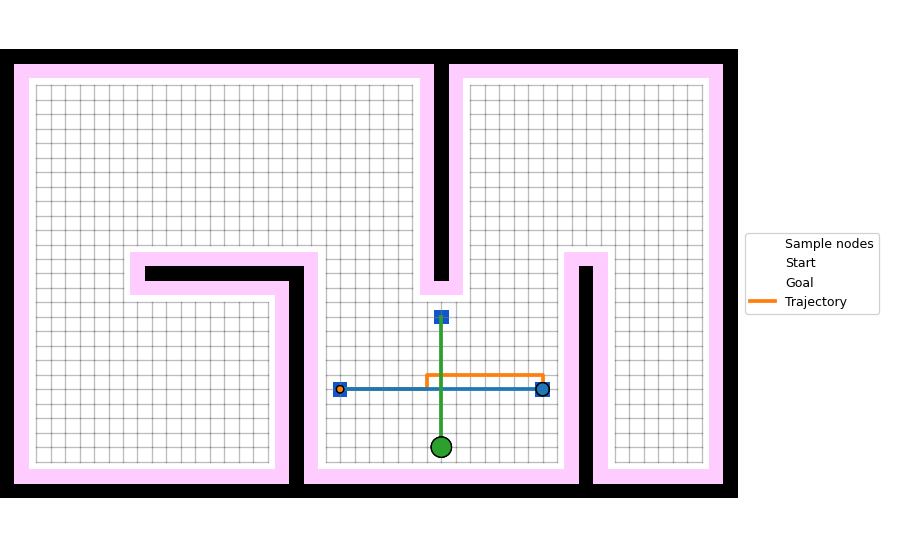

In [2]:
gif_radii, _ = run_scenario(
    "radii",
    radii={"west": 0.25, "east": 0.45, "north": 0.70},
    velocities={"west": 1.0, "east": 1.0, "north": 1.0},
)
display(Image(filename=gif_radii))

## 2. Different speeds, same radius

Every agent has radius 0.40 (pairwise clearance 0.80); speeds 2.0 / 1.0 / 0.5.

[speeds] inflation radius 1.414 | makespan 18.00 | collisions at r_i + r_j: 0
   west   radius 0.40  nominal speed 2.00  observed move speeds [2.0]  arrives t=7.00
   east   radius 0.40  nominal speed 1.00  observed move speeds [1.0]  arrives t=16.60
   north  radius 0.40  nominal speed 0.50  observed move speeds [0.5]  arrives t=18.00


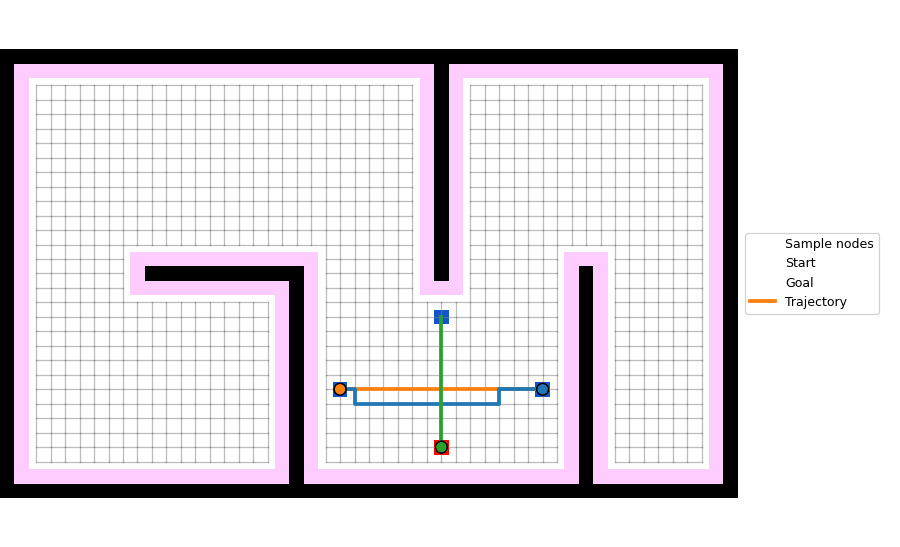

In [3]:
gif_speeds, _ = run_scenario(
    "speeds",
    radii={"west": 0.40, "east": 0.40, "north": 0.40},
    velocities={"west": 2.0, "east": 1.0, "north": 0.5},
)
display(Image(filename=gif_speeds))

## 3. Different radii and different speeds

Small and fast (`west`: r 0.25, v 2.0), medium (`east`: r 0.45, v 1.0), big and slow (`north`: r 0.70, v 0.5).

[radii_and_speeds] inflation radius 1.414 | makespan 18.00 | collisions at r_i + r_j: 0
   west   radius 0.25  nominal speed 2.00  observed move speeds [2.0]  arrives t=7.00
   east   radius 0.45  nominal speed 1.00  observed move speeds [1.0]  arrives t=17.30
   north  radius 0.70  nominal speed 0.50  observed move speeds [0.5]  arrives t=18.00


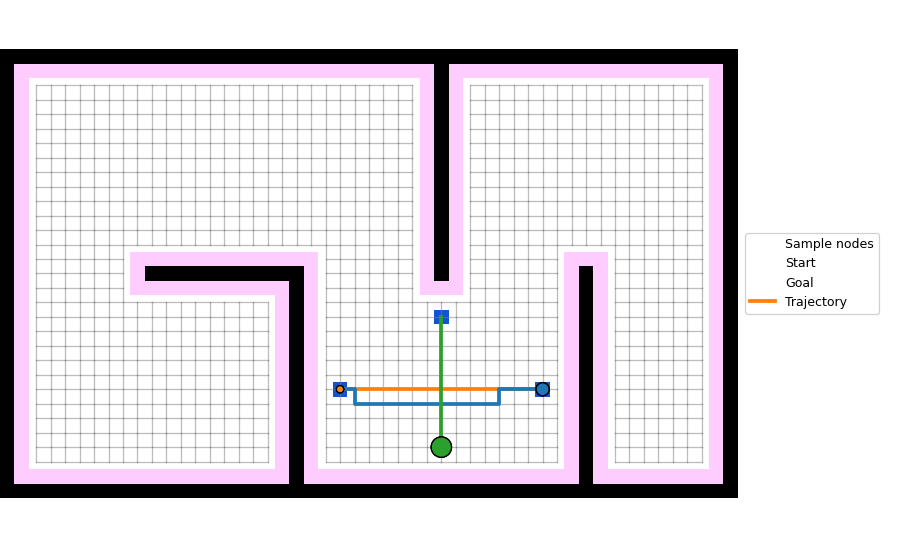

In [4]:
gif_both, summary_both = run_scenario(
    "radii_and_speeds",
    radii={"west": 0.25, "east": 0.45, "north": 0.70},
    velocities={"west": 2.0, "east": 1.0, "north": 0.5},
)
display(Image(filename=gif_both))

The solver output records both the scalar fallbacks and the per-agent values, so a checker can
re-validate the schedule with `check_collision(schedule, summary["agent_radii"])`.

In [5]:
{k: summary_both[k] for k in ("agent_radius", "agent_velocity", "agent_radii", "agent_velocities", "makespan", "flowtime")}

{'agent_radius': 0.3,
 'agent_velocity': 1.0,
 'agent_radii': {'west': 0.25, 'east': 0.45, 'north': 0.7},
 'agent_velocities': {'west': 2.0, 'east': 1.0, 'north': 0.5},
 'makespan': 18.0,
 'flowtime': 41.0}